# Predicción de peleas UFC
## Evolución del proyecto, cuotas y método de victoria

**Informe de avance para presentación**  
Proyecto de ciencia de datos: comparar información histórica de peleadores con un conjunto que también incluye cuotas del mercado.

> **Idea central:** las cuotas mejoran el resultado de este experimento, pero no hacen que una predicción sea segura. El resultado depende del periodo de prueba y no demuestra que el modelo sea mejor que el mercado.

## Resumen ejecutivo

- Empezamos con el CSV proporcionado y luego ampliamos los datos con UFCStats y una fuente que incluye **esquina roja/azul, estadísticas y cuotas históricas**.
- En el experimento con cuotas, Random Forest obtuvo **69,1 %** de aciertos; la misma configuración sin cuotas obtuvo **63,5 %**, sobre las mismas 1.499 peleas.
- En la comparación más pareja, limitada a las 1.275 peleas que tenían cuotas para ambas esquinas, el modelo acertó **71,1 %** y elegir el favorito del mercado **69,6 %**. La diferencia es pequeña y no es evidencia suficiente para afirmar que el modelo supera al mercado.
- También probamos estimar a la vez esquina y método de victoria. Esa tarea obtuvo **36,7 %** de accuracy entre seis resultados posibles; es experimental y mucho menos fiable.

**Conclusión breve:** las cuotas aportan una señal predictiva valiosa en estos datos, pero el modelo no es infalible ni garantiza resultados futuros.

## 1. Pregunta y objetivo

La pregunta principal del proyecto es: **¿podemos estimar qué esquina gana una pelea UFC usando información disponible antes del combate?**

El objetivo binario del experimento más reciente es:

- `1`: gana la esquina roja.
- `0`: gana la esquina azul.

Comparamos tres modelos de clasificación (regresión logística, Random Forest y XGBoost) con una referencia sencilla y con la selección directa del favorito del mercado. Como extensión, estimamos la combinación de esquina y método.

## 2. Datos: qué teníamos y qué añadimos

El proyecto avanzó por etapas. No todos los resultados son directamente comparables: cambian la fuente, el periodo de prueba y, en una etapa, hasta la definición de quién gana.

1. **CSV original del proyecto:** 1.477 filas y 895 columnas. Contiene información de los peleadores, pero también estadísticas de la pelea por ronda que solo se conocen después del combate; esas columnas no deben usarse para una predicción previa.
2. **UFCStats ampliado:** estadísticas históricas y resultados entre 1994 y 2026. En ese primer modelo el objetivo es si gana el primer o segundo participante listado en `BOUT`, no necesariamente rojo o azul.
3. **Ultimate UFC Dataset:** identifica esquina roja y azul e incluye estadísticas de cada lado y variables del mercado, como `R_odds` y `B_odds`. Esto permite un objetivo uniforme de esquina roja/azul y comparar el modelo con y sin cuotas.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path.cwd().resolve()
while not (PROJECT_DIR / "src" / "train_odds_model.py").is_file():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("No se encontró la carpeta ufc-predictor.")
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR / "src"))
import train_odds_model as odds_pipeline

original = pd.read_csv(PROJECT_DIR / "data" / "raw" / "data.csv", low_memory=False)
historical_dates = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "ufc_features_historicas.csv",
    usecols=["event_date"],
)["event_date"]
source = odds_pipeline.load_source()
source, verified_count, conflict_count = odds_pipeline.validate_labels_against_ufcstats(source)
features, numeric_features, categorical_features = odds_pipeline.feature_columns(source)

source_summary = pd.DataFrame([
    {
        "Fuente / etapa": "CSV original",
        "Peleas / filas": len(original),
        "Columnas / variables": len(original.columns),
        "Periodo disponible": "CSV original recibido",
        "Objetivo del modelo": "Revisar; algunas columnas son posteriores al combate",
    },
    {
        "Fuente / etapa": "UFCStats procesado",
        "Peleas / filas": len(historical_dates),
        "Columnas / variables": "Variables históricas",
        "Periodo disponible": f"{pd.to_datetime(historical_dates).min().date()} a {pd.to_datetime(historical_dates).max().date()}",
        "Objetivo del modelo": "Gana el primero o segundo en BOUT",
    },
    {
        "Fuente / etapa": "Ultimate UFC Dataset validado",
        "Peleas / filas": len(source),
        "Columnas / variables": len(features),
        "Periodo disponible": f"{source.event_date.min().date()} a {source.event_date.max().date()}",
        "Objetivo del modelo": "Gana esquina roja o azul",
    },
])
display(source_summary)
print(f"Etiquetas contrastadas con UFCStats: {verified_count:,}; discrepancias excluidas: {conflict_count}.")
print(f"Variables de entrada del modelo con cuotas: {len(features)}; columnas post-pelea excluidas del conjunto de entradas: {len(set(odds_pipeline.POST_FIGHT_COLUMNS) & set(source.columns))}.")

,Fuente / etapa,Peleas / filas,Columnas / variables,Periodo disponible,Objetivo del modelo
0,CSV original,1477,895,CSV original recibido,Revisar; algunas columnas son posteriores al c...
1,UFCStats procesado,8792,Variables históricas,1994-03-11 a 2026-10-17,Gana el primero o segundo en BOUT
2,Ultimate UFC Dataset validado,7167,109,2010-03-21 a 2026-03-28,Gana esquina roja o azul


Etiquetas contrastadas con UFCStats: 6,822; discrepancias excluidas: 2.
Variables de entrada del modelo con cuotas: 109; columnas post-pelea excluidas del conjunto de entradas: 9.


### Qué significan las esquinas roja y azul?

En cada combate, la organización asigna a un peleador la **esquina roja** y al otro la **esquina azul**. En este conjunto, `R_fighter` es quien está asignado a la esquina roja **en esa pelea** y `B_fighter` quien está asignado a la azul. Son identificadores de los dos participantes para esa pelea: no significa que un luchador sea siempre rojo o siempre azul, ni que rojo signifique "mejor", "local" o "favorito". La asignación puede cambiar entre combates.

El campo `Winner` señala cuál de esas dos esquinas ganó. Por ejemplo, si `R_fighter = Alexa Grasso`, `B_fighter = Maycee Barber` y `Winner = Red`, la ganadora fue Alexa Grasso; "roja" solo indica la esquina que le tocó en ese combate. El modelo predice la esquina ganadora; para saber el nombre, se asocia esa esquina con el nombre de la fila.

In [2]:
# Ejemplos reales del archivo: nombre asignado a cada esquina y resultado registrado.
bouts = pd.read_csv(
    PROJECT_DIR / "data" / "raw" / "external" / "ultimate_ufc_dataset.csv",
    usecols=["date", "R_fighter", "B_fighter", "Winner", "finish"],
)
bouts["Fecha"] = pd.to_datetime(bouts["date"], errors="coerce")
bouts = bouts.loc[bouts["Winner"].isin(["Red", "Blue"])].sort_values("Fecha", ascending=False).head(5).copy()
bouts["Ganador"] = bouts.apply(
    lambda row: row["R_fighter"] if row["Winner"] == "Red" else row["B_fighter"], axis=1
)
bouts["Esquina ganadora"] = bouts["Winner"].map({"Red": "Roja", "Blue": "Azul"})
bouts = bouts.rename(columns={"R_fighter": "Peleador en esquina roja", "B_fighter": "Peleador en esquina azul", "finish": "Método"})
display(bouts[["Fecha", "Peleador en esquina roja", "Peleador en esquina azul", "Esquina ganadora", "Ganador", "Método"]].reset_index(drop=True))

,Fecha,Peleador en esquina roja,Peleador en esquina azul,Esquina ganadora,Ganador,Método
0,2026-03-28,Israel Adesanya,Joe Pyfer,Azul,Joe Pyfer,KO/TKO
1,2026-03-28,Chase Hooper,Lance Gibson Jr.,Azul,Lance Gibson Jr.,KO/TKO
2,2026-03-28,Alexia Thainara,Bruna Brasil,Roja,Alexia Thainara,U-DEC
3,2026-03-28,Navajo Stirling,Bruno Lopes,Roja,Navajo Stirling,KO/TKO
4,2026-03-28,Casey O'Neill,Gabriella Fernandes,Roja,Casey O'Neill,KO/TKO


## 3. Método de evaluación

Para aproximarnos a una predicción real, **no separamos las peleas al azar**. Entrenamos con combates antiguos y reservamos fechas posteriores para prueba; todas las peleas de una misma fecha quedan en el mismo grupo.

En las entradas del modelo binario excluimos el ganador, el método, el detalle de finalización, la ronda y la duración de la pelea. Las estadísticas y cuotas se toman de las columnas incluidas en la fuente histórica. La fuente describe cuotas históricas, pero no contiene para cada pelea un sello de tiempo independiente que permita verificar la hora exacta en que se registraron; por eso no afirmamos que sean una captura en vivo garantizada antes del combate.

**Métricas:** accuracy es el porcentaje total de aciertos. Balanced accuracy promedia los aciertos por clase, lo que ayuda cuando una clase aparece más que otra. El baseline predice siempre la clase más frecuente del entrenamiento.

## 4. Primera ampliación: UFCStats sin cuotas

Esta etapa amplió el historial de peleas y las estadísticas, pero no incluía cuotas. Su objetivo era el participante primero/segundo de `BOUT`. La prueba cronológica entrenó hasta el **18-02-2023** y evaluó combates desde el **25-02-2023** hasta el **17-10-2026**.

El Random Forest obtuvo **61,4 %** en 1.920 peleas de prueba. Es un resultado de esa versión y ese objetivo: no se debe poner al lado del 69,1 % como si ambos modelos hubieran predicho exactamente las mismas peleas y esquinas.

Prueba: 1,920 peleas, 2023-02-25 a 2026-10-17.


,model,accuracy,balanced_accuracy
0,Random Forest,61.4%,59.2%
1,Regresión logística,61.1%,58.6%
2,XGBoost,60.5%,57.7%
3,Regla: clase más frecuente en train,55.8%,50.0%


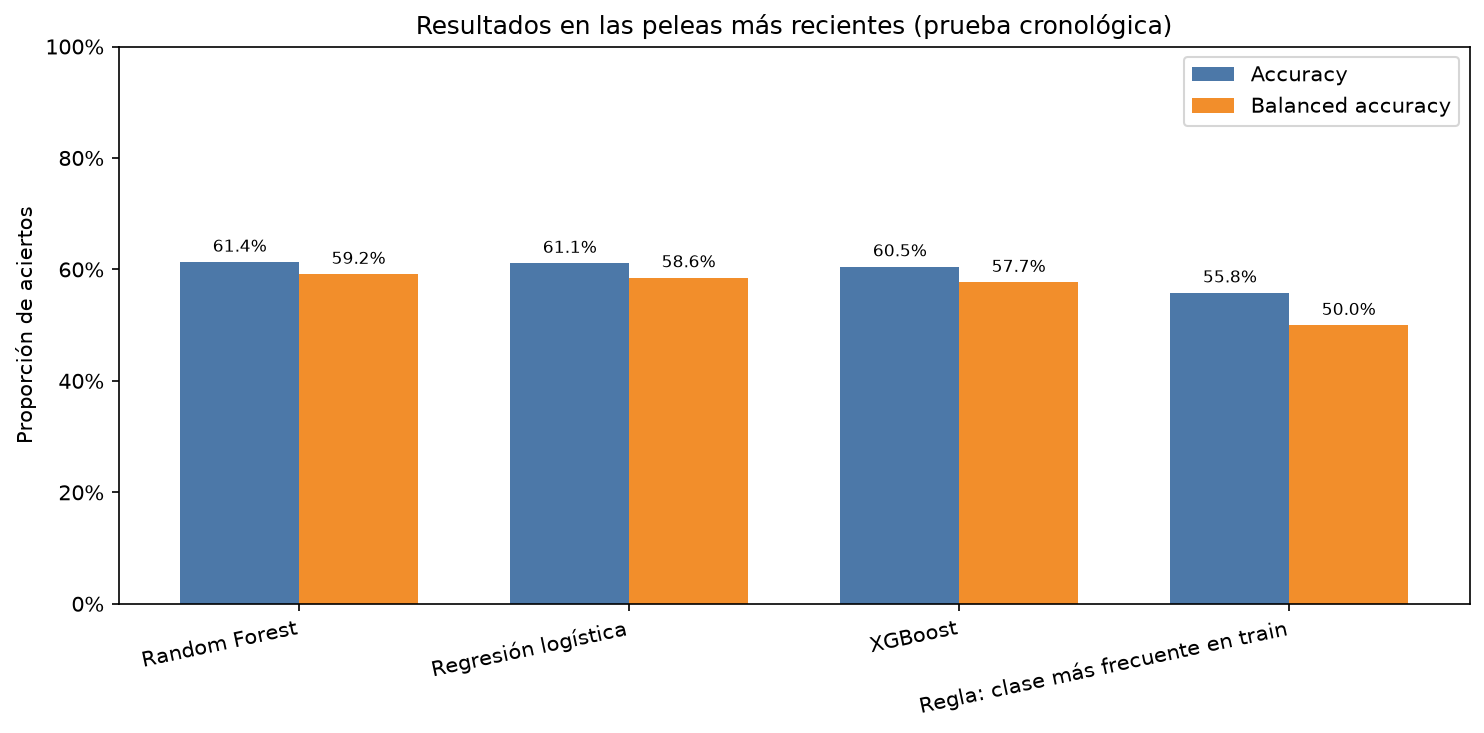

In [3]:
old_metrics = pd.read_csv(PROJECT_DIR / "reports" / "metricas_modelos_ufcstats.csv")
old_meta = __import__("joblib").load(PROJECT_DIR / "models" / "random_forest_ufcstats.joblib")
old_metrics_view = old_metrics.copy()
old_metrics_view["accuracy"] = old_metrics_view["accuracy"].map(lambda value: f"{value:.1%}")
old_metrics_view["balanced_accuracy"] = old_metrics_view["balanced_accuracy"].map(lambda value: f"{value:.1%}")
print(f"Prueba: {old_meta['test_rows']:,} peleas, {old_meta['test_start'].date()} a {old_meta['test_end'].date()}.")
display(old_metrics_view)
from IPython.display import Image
old_figure = PROJECT_DIR / "reports" / "figures" / "14_comparacion_modelos_ufcstats.png"
if old_figure.is_file():
    display(Image(filename=str(old_figure)))

## 5. Experimento con cuotas: ¿qué señal añaden?

`R_odds` y `B_odds` son las cuotas históricas asociadas a la esquina roja y azul. Resumen la expectativa del mercado, que puede incorporar información y opiniones que no estén representadas completamente en nuestras columnas de estadísticas.

Ejemplo ilustrativo: si una fila muestra `R_odds = -130` y `B_odds = +102`, el rojo aparece como favorito según esas cuotas. **Eso no significa que el rojo vaya a ganar**; es una señal que el modelo puede combinar con las demás variables.

El conjunto reciente aportó **109 variables previas según la definición del pipeline**. Se validaron 6.822 resultados coincidentes contra UFCStats y se eliminaron 2 desacuerdos de etiqueta. El corte fue hasta el **15-04-2023** para entrenamiento y del **22-04-2023 al 28-03-2026** para prueba: 5.668 entrenamientos y 1.499 pruebas.

,Modelo / referencia,Accuracy,Balanced accuracy,Peleas evaluadas
0,Regresión logística + cuotas,66.6%,64.4%,1499
1,Random Forest + cuotas,69.1%,67.2%,1499
2,XGBoost + cuotas,67.6%,65.8%,1499
3,Random Forest sin cuotas,63.5%,60.0%,1499
4,Baseline: clase más frecuente,55.8%,50.0%,1499
5,Favorito del mercado,69.6%,68.9%,1275
6,Modelo anterior (mismas peleas),62.0%,59.9%,1491


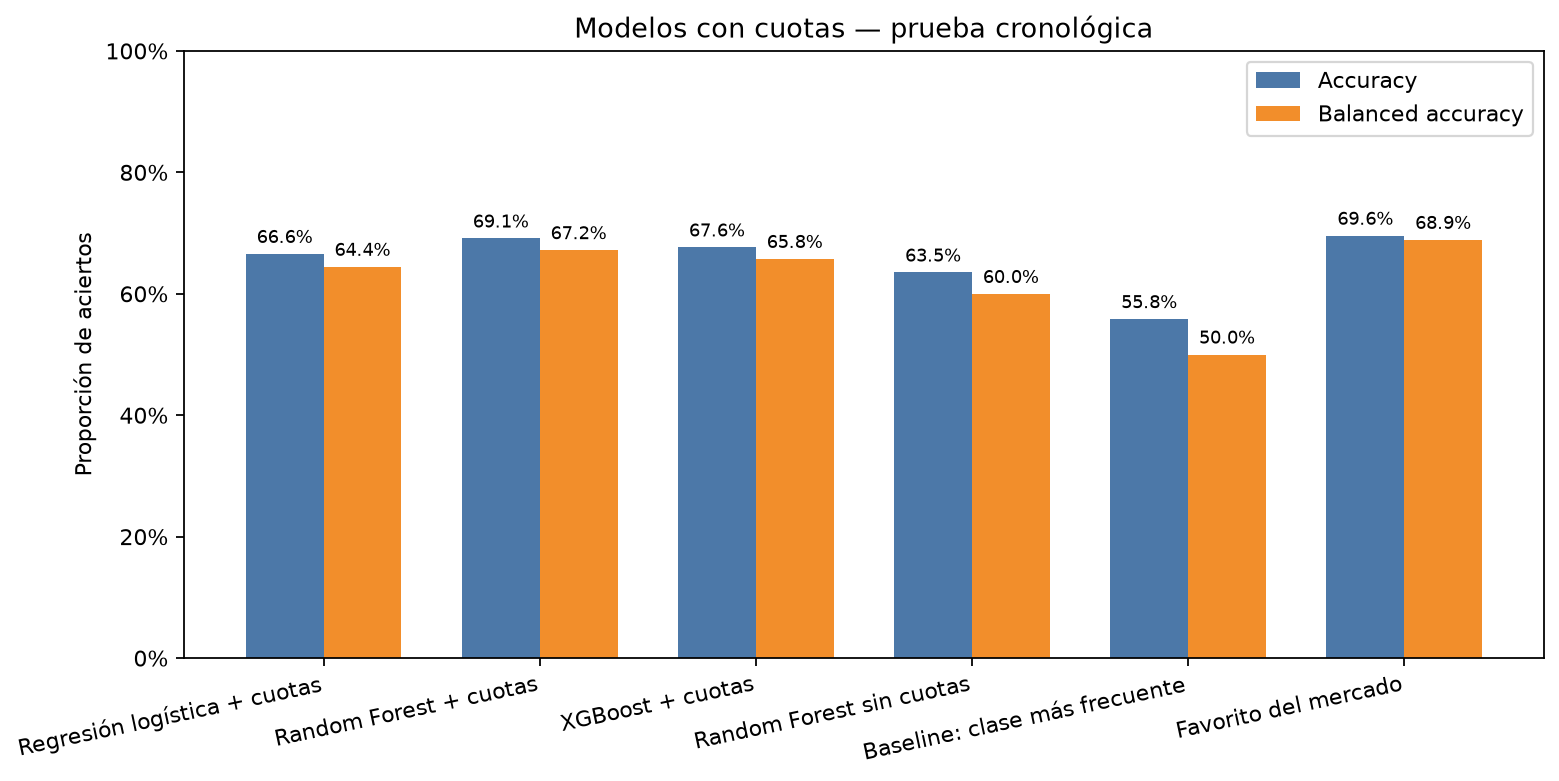

In [4]:
odds_metrics = pd.read_csv(PROJECT_DIR / "reports" / "metricas_modelos_con_cuotas.csv")
show_metrics = odds_metrics.copy()
show_metrics["accuracy"] = show_metrics["accuracy"].map(lambda value: f"{value:.1%}")
show_metrics["balanced_accuracy"] = show_metrics["balanced_accuracy"].map(lambda value: f"{value:.1%}")
show_metrics = show_metrics.rename(columns={
    "model": "Modelo / referencia",
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "n_test": "Peleas evaluadas",
})
display(show_metrics[["Modelo / referencia", "Accuracy", "Balanced accuracy", "Peleas evaluadas"]])

comparison_figure = PROJECT_DIR / "reports" / "figures" / "17_comparacion_modelos_con_cuotas.png"
if comparison_figure.is_file():
    display(Image(filename=str(comparison_figure)))

### ¿Por qué el porcentaje subió?

La comparación más clara para aislar las cuotas usa el **mismo Random Forest**, las mismas peleas y el mismo corte temporal:

- **Con estadísticas y cuotas:** 69,1 % de accuracy en 1.499 peleas.
- **Con estadísticas, sin columnas de cuotas:** 63,5 % de accuracy en esas mismas 1.499 peleas.

Eso es evidencia de que las cuotas ayudan a este modelo en esta prueba. No prueba que cada columna de cuota aporte por separado ni que el aumento se repita igual en el futuro. Las cuotas ya resumen la expectativa colectiva del mercado; son información adicional, no una señal de certeza.

## 6. Comparación justa con el favorito del mercado

El favorito del mercado solo se puede calcular en peleas con cuotas disponibles para **ambas** esquinas. Comparamos el Random Forest y el favorito en exactamente ese mismo subconjunto, en lugar de comparar porcentajes con coberturas distintas.

También hacemos una prueba pareada exploratoria: cuenta cuántas peleas acertó solo el modelo y cuántas acertó solo el favorito. Un valor p superior a 0,05 no demuestra que los métodos sean iguales; significa que esta evaluación no basta para afirmar con evidencia estadística convencional que uno sea superior.

In [5]:
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, balanced_accuracy_score

predictions = pd.read_csv(
    PROJECT_DIR / "reports" / "predicciones_prueba_con_cuotas.csv",
    parse_dates=["event_date"],
)
raw_odds = pd.read_csv(
    PROJECT_DIR / "data" / "raw" / "external" / "ultimate_ufc_dataset.csv",
    usecols=["date", "R_fighter", "B_fighter", "R_odds", "B_odds"],
)
raw_odds["event_date"] = pd.to_datetime(raw_odds["date"], errors="coerce")

def normalize_fighter(name):
    import re
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", str(name).lower())).strip()

for frame in (predictions, raw_odds):
    frame["red_key"] = frame["R_fighter"].map(normalize_fighter)
    frame["blue_key"] = frame["B_fighter"].map(normalize_fighter)

matched = predictions.merge(
    raw_odds[["event_date", "red_key", "blue_key", "R_odds", "B_odds"]],
    on=["event_date", "red_key", "blue_key"],
    how="left",
    validate="one_to_one",
)
red_odds = pd.to_numeric(matched["R_odds"], errors="coerce")
blue_odds = pd.to_numeric(matched["B_odds"], errors="coerce")
has_both_odds = red_odds.notna() & blue_odds.notna()
common = matched.loc[has_both_odds].copy()
common_red_odds = red_odds.loc[has_both_odds]
common_blue_odds = blue_odds.loc[has_both_odds]
common["favorite_red"] = common_red_odds.lt(common_blue_odds).astype(int).to_numpy()
common["actual_red"] = common["target_red"].astype(int)
common["rf_correct"] = common["predicted_red"].eq(common["actual_red"])
common["favorite_correct"] = common["favorite_red"].eq(common["actual_red"])

rf_only = int((common["rf_correct"] & ~common["favorite_correct"]).sum())
favorite_only = int((common["favorite_correct"] & ~common["rf_correct"]).sum())
discordant = rf_only + favorite_only
paired_p_value = binomtest(rf_only, discordant, 0.5).pvalue
same_fights = pd.DataFrame([
    {
        "Método": "Random Forest con estadísticas y cuotas",
        "Accuracy en las mismas peleas": accuracy_score(common["actual_red"], common["predicted_red"]),
        "Balanced accuracy": balanced_accuracy_score(common["actual_red"], common["predicted_red"]),
        "Peleas": len(common),
    },
    {
        "Método": "Favorito elegido por las cuotas",
        "Accuracy en las mismas peleas": accuracy_score(common["actual_red"], common["favorite_red"]),
        "Balanced accuracy": balanced_accuracy_score(common["actual_red"], common["favorite_red"]),
        "Peleas": len(common),
    },
])
pretty_same = same_fights.copy()
pretty_same["Accuracy en las mismas peleas"] = pretty_same["Accuracy en las mismas peleas"].map(lambda value: f"{value:.1%}")
pretty_same["Balanced accuracy"] = pretty_same["Balanced accuracy"].map(lambda value: f"{value:.1%}")
display(pretty_same)
print(f"Peleas acertadas solo por el modelo: {rf_only}; solo por el favorito: {favorite_only}.")
print(f"Prueba pareada exacta (McNemar/binomial): p = {paired_p_value:.3f}.")
print("La diferencia observada no alcanza el umbral convencional de 0,05; no afirmamos superioridad estadística.")

,Método,Accuracy en las mismas peleas,Balanced accuracy,Peleas
0,Random Forest con estadísticas y cuotas,71.1%,69.7%,1275
1,Favorito elegido por las cuotas,69.6%,68.9%,1275


Peleas acertadas solo por el modelo: 57; solo por el favorito: 38.
Prueba pareada exacta (McNemar/binomial): p = 0.064.
La diferencia observada no alcanza el umbral convencional de 0,05; no afirmamos superioridad estadística.


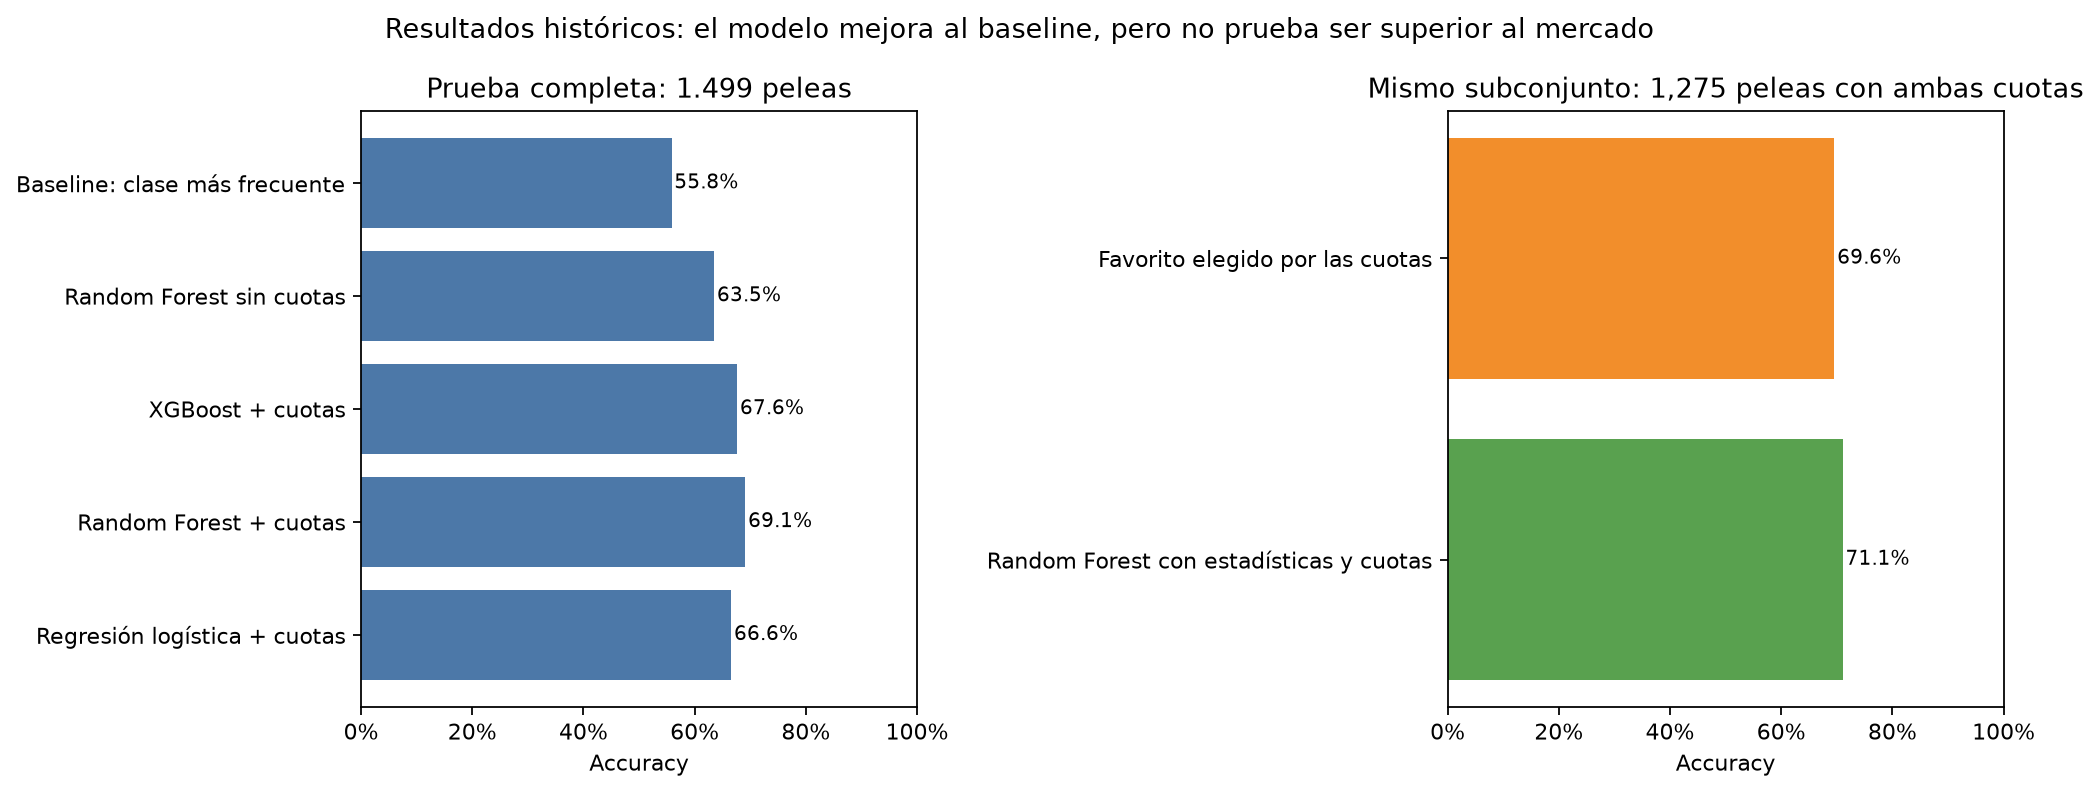

In [6]:
import matplotlib.pyplot as plt

full_compare = odds_metrics[
    odds_metrics["model"].isin([
        "Random Forest + cuotas",
        "Random Forest sin cuotas",
        "Regresión logística + cuotas",
        "XGBoost + cuotas",
        "Baseline: clase más frecuente",
    ])
].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(full_compare["model"], full_compare["accuracy"], color="#4C78A8")
axes[0].set_title("Prueba completa: 1.499 peleas")
axes[0].set_xlabel("Accuracy")
axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
for index, value in enumerate(full_compare["accuracy"]):
    axes[0].text(value + 0.005, index, f"{value:.1%}", va="center", fontsize=9)

axes[1].barh(same_fights["Método"], same_fights["Accuracy en las mismas peleas"], color=["#59A14F", "#F28E2B"])
axes[1].set_title(f"Mismo subconjunto: {len(common):,} peleas con ambas cuotas")
axes[1].set_xlabel("Accuracy")
axes[1].set_xlim(0, 1)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
for index, value in enumerate(same_fights["Accuracy en las mismas peleas"]):
    axes[1].text(value + 0.005, index, f"{value:.1%}", va="center", fontsize=9)
fig.suptitle("Resultados históricos: el modelo mejora al baseline, pero no prueba ser superior al mercado")
fig.tight_layout()
chart_path = PROJECT_DIR / "reports" / "figures" / "20_comparacion_accuracy_presentacion.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
from IPython.display import display, Image
display(Image(filename=str(chart_path)))
plt.close(fig)

## 7. Extensión: esquina y método de victoria

Como siguiente idea, entrenamos otro clasificador con seis clases: esquina roja o azul por KO/TKO, sumisión o decisión. Tiene que acertar **la esquina y el método**, por eso no se compara directamente con el 69,1 % del objetivo binario.

La prueba cronológica contiene 1.486 combates. Se excluyeron 258 filas sin método compatible o con otros desenlaces (por ejemplo, descalificación, no contest o resultado anulado). Las probabilidades suman 100 % dentro de estas seis clases, no entre todos los desenlaces posibles. No estén calibradas como probabilidades fiables.

### Cómo leer el heatmap (matriz de confusión)

- **Cada fila es lo que ocurrió realmente** en la pelea. Por ejemplo, "Esquina roja — KO/TKO" significa que ganó el peleador asignado a la esquina roja por KO/TKO.
- **Cada columna es lo que predijo el modelo.**
- **La diagonal** (de arriba a la izquierda hacia abajo a la derecha) contiene los aciertos: predicción y resultado coinciden. Las demás celdas son errores; muestran qué resultado confundió el modelo.
- El gráfico actualizado muestra en cada celda el **porcentaje dentro de esa fila** y, entre paréntesis, el número de peleas. Por eso cada fila suma aproximadamente 100 %. El color representa ese porcentaje, no el número bruto de peleas.

Ejemplo: en la fila "Esquina roja — KO/TKO" hubo 265 peleas reales de ese tipo. Si la celda diagonal dice `35 % (n=92)`, significa que el modelo identificó correctamente 92 de esas 265: alrededor de 35 %. No significa que ese resultado tenga 35 % de probabilidad en una pelea futura.

,model,accuracy,balanced_accuracy,macro_f1,n_test,train_end,test_start,test_end
0,Random Forest — esquina y método,36.7%,36.4%,0.355,1486,2023-04-22,2023-04-29,2026-03-28
1,Baseline — clase más frecuente,28.4%,16.7%,0.074,1486,2023-04-22,2023-04-29,2026-03-28


,Resultado,Recall,F1,Peleas reales
0,Esquina azul — Decisión,38.1%,0.380,344
1,Esquina azul — KO/TKO,34.8%,0.329,204
2,Esquina azul — Sumisión,34.9%,0.290,106
3,Esquina roja — Decisión,37.9%,0.411,422
4,Esquina roja — KO/TKO,34.7%,0.362,265
5,Esquina roja — Sumisión,37.9%,0.355,145


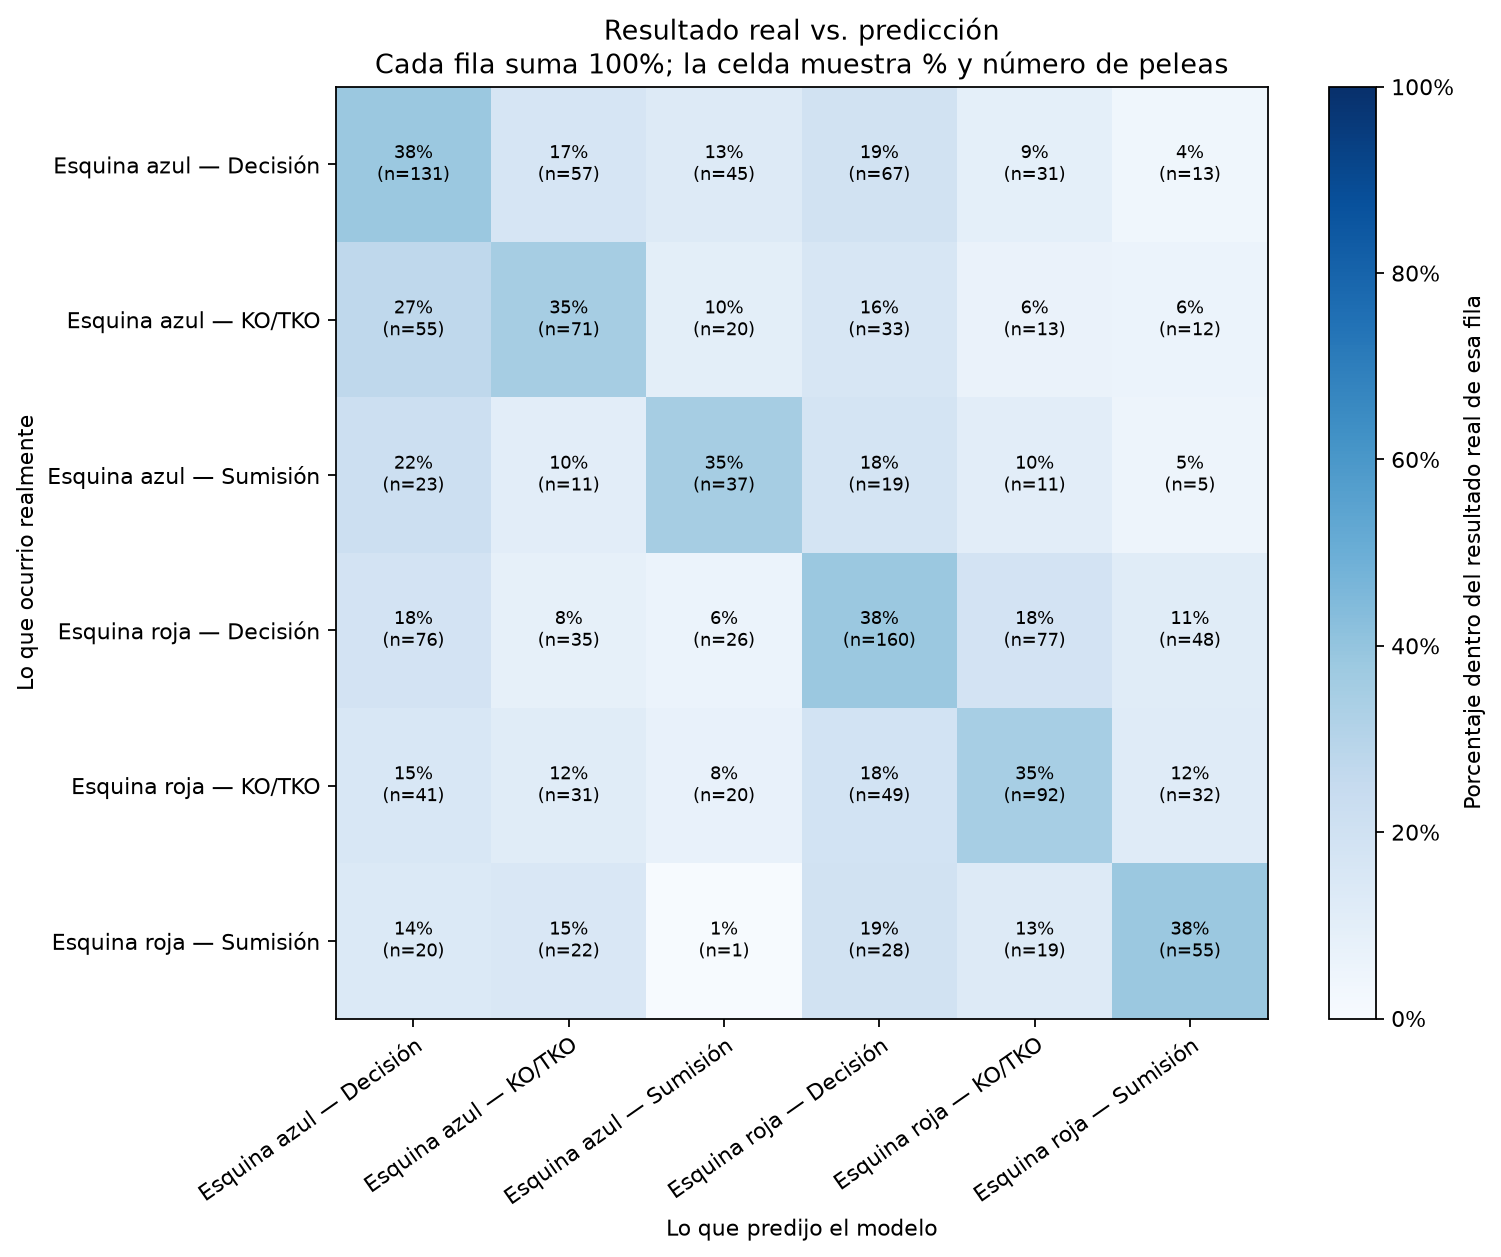

In [7]:
from sklearn.metrics import classification_report

method_metrics = pd.read_csv(PROJECT_DIR / "reports" / "metricas_metodo_victoria.csv")
method_predictions = pd.read_csv(PROJECT_DIR / "reports" / "predicciones_metodo_victoria.csv")
method_view = method_metrics.copy()
for column in ["accuracy", "balanced_accuracy"]:
    method_view[column] = method_view[column].map(lambda value: f"{value:.1%}")
method_view["macro_f1"] = method_view["macro_f1"].map(lambda value: f"{value:.3f}")
display(method_view)

per_class = classification_report(
    method_predictions["target_method_outcome"],
    method_predictions["predicted_outcome"],
    output_dict=True,
    zero_division=0,
)
class_names = sorted(method_predictions["target_method_outcome"].unique())
class_table = pd.DataFrame([
    {
        "Resultado": name,
        "Recall": per_class[name]["recall"],
        "F1": per_class[name]["f1-score"],
        "Peleas reales": int(per_class[name]["support"]),
    }
    for name in class_names
])
class_table["Recall"] = class_table["Recall"].map(lambda value: f"{value:.1%}")
class_table["F1"] = class_table["F1"].map(lambda value: f"{value:.3f}")
display(class_table)
display(Image(filename=str(PROJECT_DIR / "reports" / "figures" / "19_matriz_confusion_metodo_victoria.png")))

## 8. Interpretación honesta y limitaciones

1. **Las cuotas ayudan en el conjunto evaluado:** 69,1 % con cuotas frente a 63,5 % sin cuotas en las mismas peleas. El mercado resume información adicional; no es una garantía.
2. **No se ha demostrado que el modelo supere al mercado:** en las mismas 1.275 peleas el resultado fue 71,1 % frente a 69,6 %, pero la ventaja observada (1,5 puntos porcentuales) no fue concluyente en la prueba pareada (`p = 0,064`).
3. **Las versiones históricas no son comparaciones directas:** cambian fechas, esquinas/orden de `BOUT` y cobertura de datos.
4. **Hay incertidumbre y datos faltantes:** atletas nuevos, lesiones, cambios de campamento, reemplazos de última hora y calidad de datos afectan el resultado.
5. **Las cuotas no tienen una hora de captura verificable en nuestro archivo:** para una prueba prospectiva se deben guardar las cuotas y las estadísticas tal como existían antes del evento.
6. **La predicción de método es una función experimental:** 36,7 % para seis clases; debe mostrarse con cautela y no como una recomendación de apuestas.

## 9. Conclusión y siguientes pasos

El proyecto avanzó de una primera tabla de UFC a datos con más historial y, después, a un experimento con cuotas y un objetivo claro de esquina roja/azul. La mejora de 63,5 % a 69,1 % respalda que las cuotas aportan señal en esta prueba; la comparación pareada con el favorito del mercado no basta para decir que nuestro modelo lo vence.

**Siguientes pasos:** (1) conservar una evaluación prospectiva con los datos disponibles antes de las peleas; (2) guardar fecha y fuente de las cuotas; (3) comprobar si las probabilidades estén calibradas; (4) mejorar la presentación de la predicción de método; y (5) después construir una página web que muestre ganador estimado, métodos y comparación de estadísticas.

## Fuentes y reproducibilidad

- Dataset de cuotas y estadísticas: [Ultimate UFC Dataset](https://github.com/shortlikeafox/ultimate_ufc_dataset), atribución CC BY 4.0 según la información del proyecto. La descarga local está en `data/raw/external/ultimate_ufc_dataset.csv`.
- Datos UFCStats: recopilación de [Greco1899/scrape_ufc_stats](https://github.com/Greco1899/scrape_ufc_stats), guardada aparte en `data/raw/ufcstats/`.
- El CSV original se conserva en `data/raw/data.csv`.

Por defecto, ejecuta las celdas en orden para consultar los resultados guardados. Para actualizar los datos y volver a entrenar, desde la carpeta `ufc-predictor` ejecuta:

```powershell
python src\train_updated_model.py --refresh
python src\train_odds_model.py --refresh
```

La actualización es manual. Después de entrenar, vuelve a ejecutar este notebook para cargar las nuevas tablas y gráficas.